# 02 — How the mock web is built

The mock is built in five steps, none of which runs a filament finder:

1. **Initial conditions.** A Gaussian random field, grown to z = 0 with the Zel'dovich approximation.
2. **Voids.** Spheres grown about the density minima until their mean density rises to 0.2 ρ̄,
   nested (a void whose centre lies inside a larger one is rejected) and trimmed until no two overlap.
3. **Cells.** A power-weighted (Laguerre) tessellation of the void centres, with weights fitted so each
   cell's volume is proportional to its void's radius cubed. This gives a broad range of void sizes,
   which an ordinary Voronoi tessellation cannot.
4. **Skeleton.** Nodes are the vertices of the tessellation, filaments the straight edges between them,
   in closed form.
5. **Particles.** Particles are pushed out of their cells onto walls, filaments and nodes; walls and
   filaments are given a thickness; the filament and node matter is gathered into NFW haloes; and a
   fraction of the particles is replaced by the 2LPT realisation of the same initial conditions, which
   puts faint, uncollapsed structure back into the voids.

This notebook runs each step by hand with the package's building blocks, using a 50 Mpc/h box with
64³ particles. `gtweb.generate_mock` does all of it in one call.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

try:
    import gtweb
except ImportError:                       # running from a clone without `pip install -e .`
    sys.path.insert(0, str(Path.cwd().parent))
    import gtweb

plt.style.use(Path(gtweb.__file__).parent / "gtweb.mplstyle")
print("gtweb", gtweb.__version__)
from matplotlib.collections import LineCollection
from gtweb import ic, geometry, web, particles, lpt, groundtruth

BOX, NGRID, SEED = 50.0, 64, 1

gtweb 1.0.1


## Step 1 — initial conditions

`gaussian_psi1` returns the Zel'dovich displacement Ψ₁ on the Lagrangian grid at z = 0 linear
amplitude; the linear density is δ = −∇·Ψ₁, and the particle load is x = q + Ψ₁.

rms |Psi1| = 5.88 Mpc/h,  rms delta_lin = 3.46


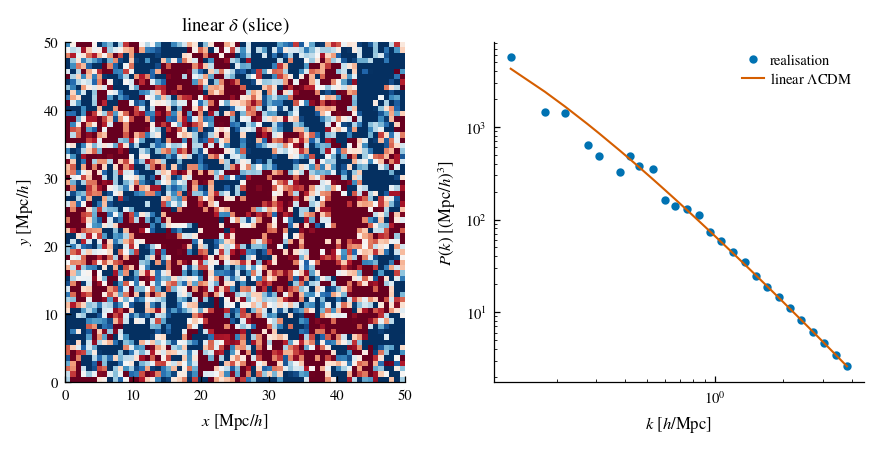

In [2]:
d = ic.gaussian_psi1(BOX, NGRID, seed=SEED)
psi1 = d["psi1"]
delta_lin, _ = lpt.linear_density_from_psi1(psi1, BOX)
x_za = ic.za_positions(psi1, BOX)
print(f"rms |Psi1| = {d['rms_psi1']:.2f} Mpc/h,  rms delta_lin = {delta_lin.std():.2f}")

k, pk = ic.measure_pk(delta_lin.astype(float), BOX)
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.0))
axs[0].imshow(delta_lin[:, :, NGRID // 2].T, origin="lower", extent=[0, BOX, 0, BOX], cmap="RdBu_r",
              vmin=-3, vmax=3)
axs[0].set(title=r"linear $\delta$ (slice)", xlabel=r"$x$ [Mpc/$h$]", ylabel=r"$y$ [Mpc/$h$]")
from gtweb import cosmology
axs[1].loglog(k, pk, "o", ms=3, label="realisation")
axs[1].loglog(k, cosmology.linear_Pk(k), label=r"linear $\Lambda$CDM")
axs[1].set(xlabel=r"$k$ [$h$/Mpc]", ylabel=r"$P(k)$ [(Mpc/$h$)$^3$]")
axs[1].legend()
plt.show()

## Step 2 — voids

The Zel'dovich particles are assigned to a grid with cell 0.78 Mpc/h and smoothed with a 1.5 Mpc/h
Gaussian. Around each minimum a sphere grows until its mean enclosed density reaches 0.2 ρ̄.
Candidates are accepted largest first; a candidate whose centre lies inside an accepted void is
rejected (small voids nest inside large ones); finally radii are trimmed until no two spheres overlap.

77 nested voids -> 69 after trimming to tangency; radii P10/50/90 = [2.1  3.22 5.74] Mpc/h
the spheres fill 0.21 of the box


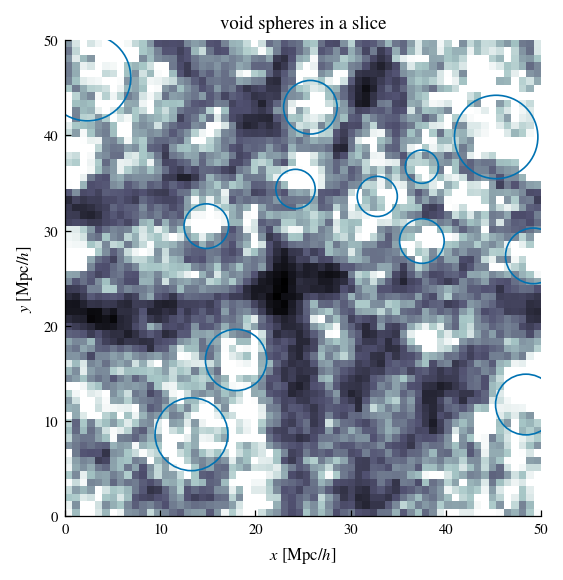

In [3]:
grid = int(round(BOX / (100 / 128)))
opd = geometry.ic_one_plus_delta(x_za, grid, BOX)
c_all, r_all = geometry.spherical_voids(opd, BOX, rho_v=0.2, smooth=1.5, r_min=1.5, r_max=0.22 * BOX)
centres, radii = geometry.shrink_to_tangency(c_all, r_all, BOX, 1.5)
print(f"{len(c_all)} nested voids -> {len(centres)} after trimming to tangency; "
      f"radii P10/50/90 = {np.percentile(radii, [10, 50, 90]).round(2)} Mpc/h")
print(f"the spheres fill {(4 / 3 * np.pi * radii ** 3).sum() / BOX ** 3:.2f} of the box")

zc = BOX / 2
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(np.log10(opd[:, :, int(zc / BOX * grid)] + 0.05).T, origin="lower", extent=[0, BOX, 0, BOX], cmap="bone_r")
for c, r in zip(centres, radii):
    dzc = abs(c[2] - zc)
    if dzc < r:                                                   # sphere cuts the slice
        ax.add_patch(plt.Circle(c[:2], np.sqrt(r ** 2 - dzc ** 2), fill=False, color="#0072B2", lw=0.8))
ax.set(xlim=(0, BOX), ylim=(0, BOX), title="void spheres in a slice", xlabel=r"$x$ [Mpc/$h$]", ylabel=r"$y$ [Mpc/$h$]")
plt.show()

## Step 3 — cells

The spheres fill only part of the box, so an ordinary Voronoi tessellation of their centres would
make every cell about the same size (set by the spacing of the centres). In a power (Laguerre)
tessellation a point x belongs to the centre cᵢ that minimises |x − cᵢ|² − wᵢ; the weights wᵢ are
fitted by gradient ascent so that each cell's volume is proportional to its sphere's radius cubed.

ordinary Voronoi : cell radius P10/50/90 = 6.47/7.68/8.34 Mpc/h, P90/P10 = 1.29, max 8.8
fitted Laguerre  : cell radius P10/50/90 = 3.57/5.42/9.65 Mpc/h, P90/P10 = 2.70, max 16.1


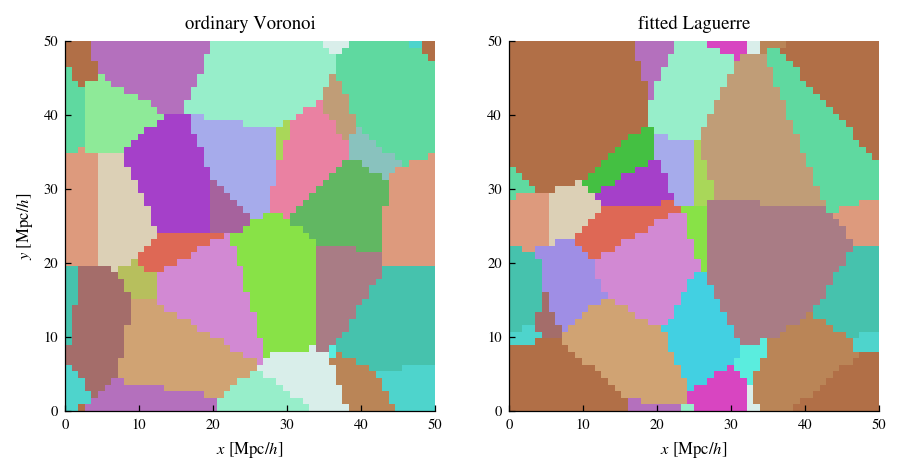

In [4]:
fit_grid = int(round(BOX / (100 / 112)))
w = geometry.laguerre_fit(centres, radii, BOX, grid=fit_grid, iters=260)

R_vor, _, own_vor = geometry.power_cells(centres, np.zeros(len(centres)), fit_grid, BOX, 64)
R_lag, _, own_lag = geometry.power_cells(centres, w, fit_grid, BOX, 64)
for name, R in (("ordinary Voronoi", R_vor), ("fitted Laguerre", R_lag)):
    p10, p50, p90 = np.percentile(R, [10, 50, 90])
    print(f"{name:17s}: cell radius P10/50/90 = {p10:.2f}/{p50:.2f}/{p90:.2f} Mpc/h, P90/P10 = {p90 / p10:.2f}, max {R.max():.1f}")

rng = np.random.default_rng(0)
cmap = plt.matplotlib.colors.ListedColormap(rng.uniform(0.25, 0.95, (len(centres), 3)))
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.4))
for ax, own, t in ((axs[0], own_vor, "ordinary Voronoi"), (axs[1], own_lag, "fitted Laguerre")):
    ax.imshow(own.reshape(fit_grid, fit_grid, fit_grid)[:, :, fit_grid // 2].T, origin="lower",
              extent=[0, BOX, 0, BOX], cmap=cmap, interpolation="nearest")
    ax.set(title=t, xlabel=r"$x$ [Mpc/$h$]")
axs[0].set_ylabel(r"$y$ [Mpc/$h$]")
plt.show()

## Step 4 — the skeleton

The nodes are the vertices of the power tessellation (the weighted circumcentres of the dual regular
triangulation) and the filaments are the straight edges joining them. Note that every node of a
three-dimensional tessellation joins exactly four edges, so the mock cannot represent nodes of higher
connectivity (real clusters connect to more filaments).

In a plane cut through the box the cell boundaries are walls, and a filament shows only as the point
where it pierces the plane, at a corner where three cells meet. The left panel checks this: every
piercing point lands on such a corner. The right panel projects a 10 Mpc/h slab to show the network
itself.

430 nodes, 860 filaments; node degree: 100% of nodes have 4
58 filaments pierce the mid-plane; 119 nodes in the 10 Mpc/h slab


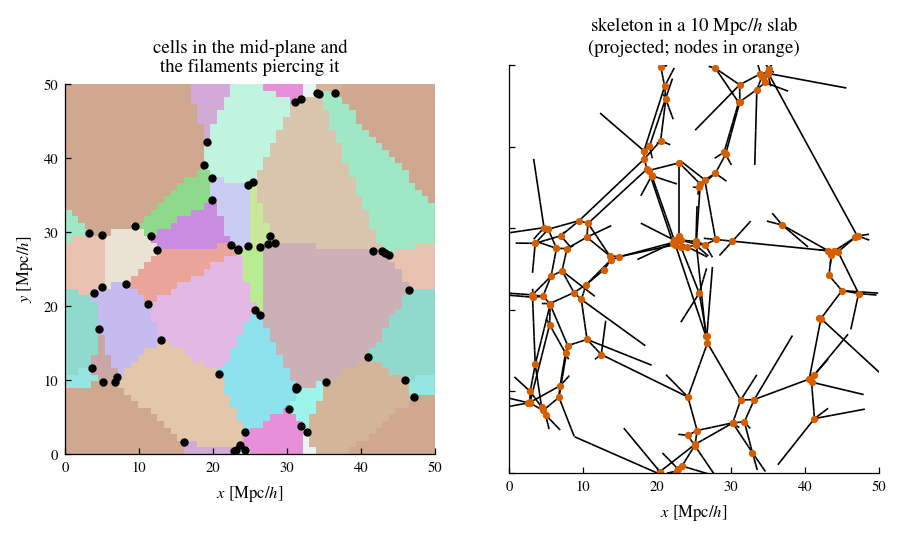

In [5]:
wb = web.build_web_from_geometry(centres, w, BOX)
deg = np.asarray(wb["node_degree"])
print(f"{len(wb['nodes'])} nodes, {int(wb['n_filaments'])} filaments; node degree: "
      f"{np.mean(deg == 4):.0%} of nodes have 4")
def spine_segments_in_slab(spines, box, zc, dz):
    """Pieces of the (wrapped) spines inside the slab |z - zc| < dz, as 2D segments for plotting."""
    segs = []
    for s in spines:
        p = np.asarray(s, float)
        d = np.diff(p, axis=0); d -= box * np.round(d / box)          # spines are stored wrapped
        p0 = p[:-1] % box
        for a, step in zip(p0, d):
            b = a + step
            za, zb = a[2], b[2]
            lo, hi = zc - dz, zc + dz
            if max(za, zb) < lo or min(za, zb) > hi:
                continue
            t0, t1 = 0.0, 1.0
            if zb != za:                                                  # clip the segment to the slab
                ta, tb = (lo - za) / (zb - za), (hi - za) / (zb - za)
                t0, t1 = max(0.0, min(ta, tb)), min(1.0, max(ta, tb))
            if t1 > t0:
                segs.append([(a + t0 * step)[:2], (a + t1 * step)[:2]])
    return segs


def piercing_points(spines, box, zc):
    """Points where the spines cross the plane z = zc."""
    pts = []
    for s in spines:
        p = np.asarray(s, float)
        d = np.diff(p, axis=0); d -= box * np.round(d / box)
        for a, step in zip(p[:-1] % box, d):
            if (a[2] - zc) * (a[2] + step[2] - zc) < 0:
                pts.append((a + (zc - a[2]) / step[2] * step)[:2] % box)
    return np.array(pts)


k = fit_grid // 2
zc = (k + 0.5) * BOX / fit_grid                                         # centre of the plotted cell layer
pierce = piercing_points(wb["spines"], BOX, zc)
nodes = np.asarray(wb["nodes"])
DZ = 5.0
in_slab = np.abs((nodes[:, 2] - zc + BOX / 2) % BOX - BOX / 2) < DZ
print(f"{len(pierce)} filaments pierce the mid-plane; {in_slab.sum()} nodes in the {2 * DZ:.0f} Mpc/h slab")

fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.6), sharey=True)
axs[0].imshow(own_lag.reshape(fit_grid, fit_grid, fit_grid)[:, :, k].T, origin="lower",
              extent=[0, BOX, 0, BOX], cmap=cmap, interpolation="nearest", alpha=0.6)
axs[0].plot(pierce[:, 0], pierce[:, 1], "o", ms=3, color="k")
axs[0].set(title="cells in the mid-plane and\nthe filaments piercing it")
axs[1].add_collection(LineCollection(spine_segments_in_slab(wb["spines"], BOX, zc, DZ), colors="k", lw=0.8))
axs[1].plot(nodes[in_slab, 0], nodes[in_slab, 1], "o", ms=2.5, color="#D55E00")
axs[1].set(title=f"skeleton in a {2 * DZ:.0f} Mpc/$h$ slab\n(projected; nodes in orange)")
for ax in axs:
    ax.set(xlim=(0, BOX), ylim=(0, BOX), xlabel=r"$x$ [Mpc/$h$]")
axs[0].set_ylabel(r"$y$ [Mpc/$h$]")
plt.show()

## Step 5 — particles

**Collapse.** Each particle is pushed away from its cell's centre, x → cᵢ + (1 + Tᵢ)(x − cᵢ), and if this
takes it out of the cell it is projected onto the nearest face, edge or vertex, so it ends in a void,
wall, filament or node. Tᵢ = 0.98 (Rᵢ / median R)^½ grows with the void radius, so large voids empty
further.

mass fractions: {'void': 0.01, 'wall': 0.226, 'filament': 0.417, 'node': 0.347}


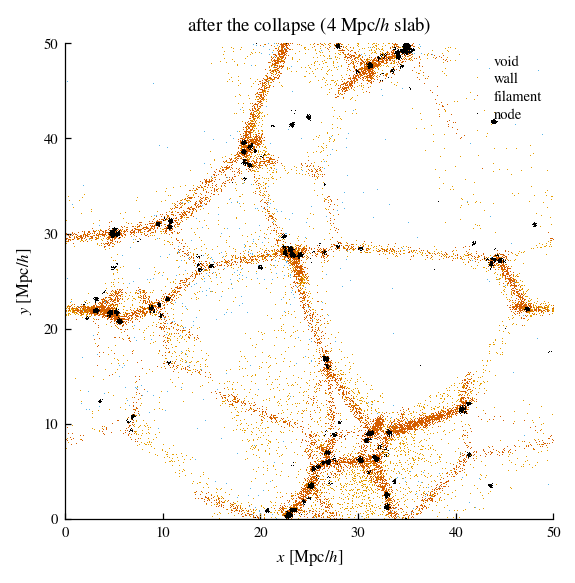

In [6]:
pos, stage = particles.cascade_onto_geometry(x_za, centres, w, radii, BOX, seed=SEED, T_base=0.98, T_exp=0.5)
names = ["void", "wall", "filament", "node"]
print("mass fractions:", {n: round(float(np.mean(stage == i)), 3) for i, n in enumerate(names)})

rng_t = np.random.default_rng(2000 + SEED)                           # wall / filament thickness 0.25 Mpc/h
extra = np.where(stage == 1, 0.25, 0.0) + np.where(stage == 2, 0.25, 0.0)
pos = (pos + rng_t.normal(0, 1, pos.shape) * extra[:, None]) % BOX

sl = np.abs(pos[:, 2] - BOX / 2) < 2.0
fig, ax = plt.subplots(figsize=(4.2, 4.2))
for i, col in zip(range(4), ["#56B4E9", "#E69F00", "#D55E00", "k"]):
    m = sl & (stage == i)
    ax.plot(pos[m, 0], pos[m, 1], ",", color=col, label=names[i], rasterized=True)
ax.set(xlim=(0, BOX), ylim=(0, BOX), title="after the collapse (4 Mpc/$h$ slab)", xlabel=r"$x$ [Mpc/$h$]", ylabel=r"$y$ [Mpc/$h$]")
ax.legend(markerscale=20, loc="upper right")
plt.show()

**Haloes.** The filament and node particles are gathered into haloes: each joins its nearest density
peak (found after 0.3 Mpc/h smoothing) and every peak with at least 20 particles is redrawn as an NFW
profile of concentration 6. Forty per cent of the filament particles stay where they are, as smooth
bridges between haloes.

**Diffuse matter.** Finally 32 per cent of the particles are replaced by the 2LPT realisation of the
same initial conditions, which fills the voids with faint structure.

1055 haloes, M = 8.1e+11-1.6e+14 Msun/h


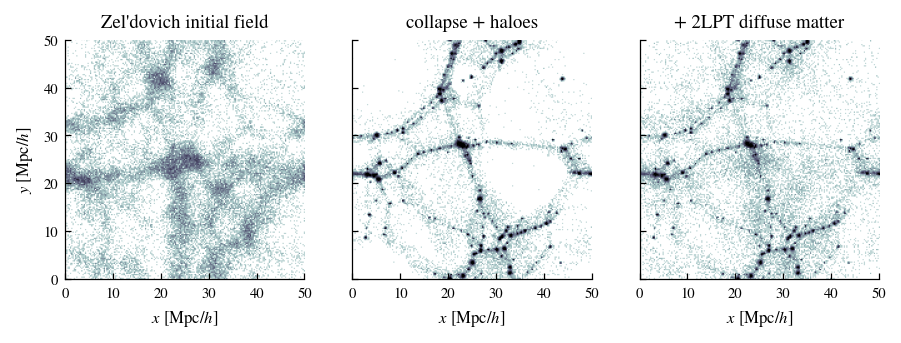

In [7]:
pos_h, stage_h, halo_cat = particles.halo_model_population(
    pos, stage, BOX, seed=SEED, grid=int(round(BOX / (100 / 512))), diffuse_frac=0.4, return_catalogue=True)
print(f"{len(halo_cat['positions'])} haloes, M = {halo_cat['mass'].min():.1e}-{halo_cat['mass'].max():.1e} Msun/h")

p1s, p2, r1, r2 = lpt.truncated_2lpt(psi1, BOX, Rs=0.0)
x_2lpt = lpt.lpt_positions(p1s, p2, BOX)
rng_m = np.random.default_rng(3000 + SEED)
nd = int(round(0.32 * len(pos_h)))
final = np.vstack([pos_h[rng_m.choice(len(pos_h), len(pos_h) - nd, replace=False)],
                   x_2lpt[rng_m.choice(len(x_2lpt), nd, replace=False)]])
def slab_image(pos, box, zc, dz, bins=256):
    sub = pos[np.abs(pos[:, 2] - zc) < dz]
    H, _, _ = np.histogram2d(sub[:, 0], sub[:, 1], bins=bins, range=[[0, box], [0, box]])
    return np.log10(1.0 + H / max(H.mean(), 1e-12)).T
fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharey=True)
for ax, p, t in ((axs[0], x_za, "Zel'dovich initial field"), (axs[1], pos_h, "collapse + haloes"),
                 (axs[2], final, "+ 2LPT diffuse matter")):
    ax.imshow(slab_image(np.asarray(p), BOX, BOX / 2, 3.0, bins=192), origin="lower", extent=[0, BOX, 0, BOX],
              cmap="bone_r", vmax=1.6)
    ax.set(title=t, xlabel=r"$x$ [Mpc/$h$]")
axs[0].set_ylabel(r"$y$ [Mpc/$h$]")
plt.show()

## The ground truth

The truth is the skeleton of step 4, which never changes. What is measured on the final particle field
is each filament's density contrast (the mean ρ/ρ̄ along its spine, on a 0.5 Mpc/h-smoothed grid) and
each node's mass within 1.5 Mpc/h, so you can ask how recovery depends on how strong a filament is.

Because the diffuse matter is not tied to the tessellation, some of it forms faint structure of its
own away from the true spines. A finder that detects it is charged with a false detection, so read
purity with that in mind (in the paper's mock, 80 per cent of the overdense mass lies within
1.5 Mpc/h of a true spine).

In [8]:
gt, nodes_cat, walls_cat, web_geom = groundtruth.assemble_ground_truth(wb, centres, w, final, BOX)
c = np.asarray(gt["filament_target_contrast"])
print(f"filament contrast rho/mean: P10/50/90 = {np.percentile(c, [10, 50, 90]).round(1)}; "
      f"{np.mean(c >= 1):.0%} of filaments are overdense")

filament contrast rho/mean: P10/50/90 = [ 7.2 20.9 65.6]; 100% of filaments are overdense
